In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/3")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    proj_root = Path.cwd().resolve()
    if proj_root.name == "3":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 3.3 初めてのカーネル (`First Kernel and Red Zone Architecture`)
## — ブートローダからの脱皮・ExitBootServicesの主権移譲・ELFエントリポイント抽出とレッドゾーンの罠

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/3/3.3_First_Kernel_and_Red_Zone.ipynb)

本節は、『ゼロからのOS自作入門』**第3章 画面表示の練習とブートローダ**の第3節 **「3.3 初めてのカーネル」**（公式コミットタグ `osbook_day03a`）に対応する完全自己完結型解説ノートブックです。

---

### 🎯 本節の学習目標と技術的動機

1. **なぜブートローダ（UEFIアプリ）とカーネルを分離するのか？（動機と責務境界）**:
   - 前章（第2章）までで作成した `Loader.efi` は、UEFI ファームウェアの上で動作する一介の「UEFI アプリケーション」に過ぎませんでした。
   - UEFI アプリケーションの動作中は、メモリの割り当てやハードウェアの管理権限がファームウェア（UEFI Boot Services）に握られており、OS として自由にメモリレイアウトを再構成したり、独自の割り込みハンドラを設定することができません。
   - そこで、ブートローダの役割を **「ストレージからカーネル本体をメモリ上に読み込み、ファームウェアからハードウェアの全権を奪取して、カーネルへ実行を委譲する」** という初期化特化ツールと位置づけ、その後の永続的な OS 機能を担う **「カーネル（Kernel）」** を完全に独立した ELF バイナリとして作成・起動します。

2. **UEFI Boot Services の終了と MapKey リトライ機構**:
   - `gBS->ExitBootServices()` を呼び出すことで、UEFI の動的メモリ管理やファイルアクセス等のファームウェア機能を破棄し、CPU のハードウェア主権を OS 側へ完全移行します。
   - メモリ確保やファームウェアイベントによって内部のメモリマップ鍵（`MapKey`）が無効化される問題に対し、なぜ再取得（リトライ）が必要になるのかを徹底解剖します。

3. **ELF64 ヘッダとエントリポイントのオフセット計算数理**:
   - `UINT64 entry_addr = *(UINT64*)(kernel_base_addr + 24);` という C 言語コードが、なぜ 64 ビット ELF ヘッダ（`Elf64_Ehdr`）のエントリポイント（`e_entry`）を正確にデリファレンスできるのかを、バイナリレイアウトとオフセット数理から導出します。

4. **【重要コラム 3.1】System V AMD64 ABI レッドゾーン（Red Zone）の罠**:
   - x86-64 の標準呼び出し規約である System V AMD64 ABI に規定された **「Red Zone（スタックポインタ RSP の下 128 バイト）」** の仕組みとコンパイラ最適化の恩恵。
   - なぜ OS カーネル開発では Red Zone を無効化する `-mno-red-zone` が**絶対必須**なのか？（非同期ハードウェア割り込みや CPU 例外が発生した瞬間に CPU が自動実行するスタック PUSH 動作とメモリ破壊の致命的メカニズム）。


## 1. MikanOS ブートローダからカーネルへの主権移譲アーキテクチャ

ブートローダ（`MikanLoaderPkg/Main.c`）がカーネル（`kernel/main.cpp`）を読み込んで起動するまでのライフサイクルは、以下の **4つのフェーズ（Sequential Phases）** で進行します。

```mermaid
flowchart TD
    subgraph Phase1["Phase 1: カーネル探索とファイルサイズ取得"]
        A1["OpenRootDir: ルートディレクトリを開く"] --> A2["root_dir->Open(..., L'\\kernel.elf')"]
        A2 --> A3["kernel_file->GetInfo(&gEfiFileInfoGuid, ...)"]
        A3 --> A4["kernel_file_size を取得"]
    end

    subgraph Phase2["Phase 2: 1MiB 物理メモリ確保とバイナリ読み込み"]
        B1["gBS->AllocatePages(AllocateAddress, 0x100000, pages)"] --> B2["kernel_file->Read(..., (VOID*)0x100000)"]
        B2 --> B3["物理アドレス 0x100000 に ELF バイナリが常駐"]
    end

    subgraph Phase3["Phase 3: ExitBootServices によるハードウェア主権奪取"]
        C1["gBS->ExitBootServices(image_handle, memmap.map_key)"] --> C2{"成功？ (EFI_SUCCESS)"}
        C2 -- "No (MapKey 不一致)" --> C3["GetMemoryMap(&memmap) で最新キー再取得"]
        C3 --> C4["gBS->ExitBootServices 再呼び出し"]
        C2 -- "Yes" --> C5["UEFI Boot Services 終了 (主権移譲完了)"]
        C4 --> C5
    end

    subgraph Phase4["Phase 4: ELF エントリポイント抽出とカーネル突入"]
        D1["UINT64 entry_addr = *(UINT64*)(0x100000 + 24)"] --> D2["EntryPointType* entry_point = (EntryPointType*)entry_addr"]
        D2 --> D3["entry_point(): CALL 命令実行"]
        D3 --> D4["KernelMain(): while(1) __asm__('hlt')"]
    end

    Phase1 --> Phase2 --> Phase3 --> Phase4
```

### なぜ物理アドレス `0x100000` (1MiB) に配置するのか？

x86 アーキテクチャの歴史において、先頭 1MiB（`0x00000000` 〜 `0x000FFFFF`）はレガシー BIOS 時代のリアルモード（16ビット）がアクセス可能な全メモリ空間でした。
この領域には以下のような重要なハードウェア予約領域が密集しています：
- `0x00000` 〜 `0x003FF`: リアルモード割り込みベクタテーブル (IVT)
- `0x00400` 〜 `0x004FF`: BIOS データ領域 (BDA)
- `0xA0000` 〜 `0xBFFFF`: VGA グラフィックスフレームバッファ (VRAM)
- `0xC0000` 〜 `0xFFFFF`: ビデオ BIOS ROM / システム BIOS ROM

もしカーネルを先頭 1MiB 未満のアドレスに配置しようとすると、これらのファームウェアやハードウェア MMIO 領域と衝突し、システムが予期せずハングアップする危険性があります。
そのため、多くの OS カーネル（Linux カーネルを含む）は、この 1MiB 境界の直後である **`0x100000` (1MiB: 1048576 バイト)** をカーネルのベースアドレスとして採用する伝統があります。

高解像度図版を生成しました: result/fig3_05_kernel_loading_and_entry_flow.png


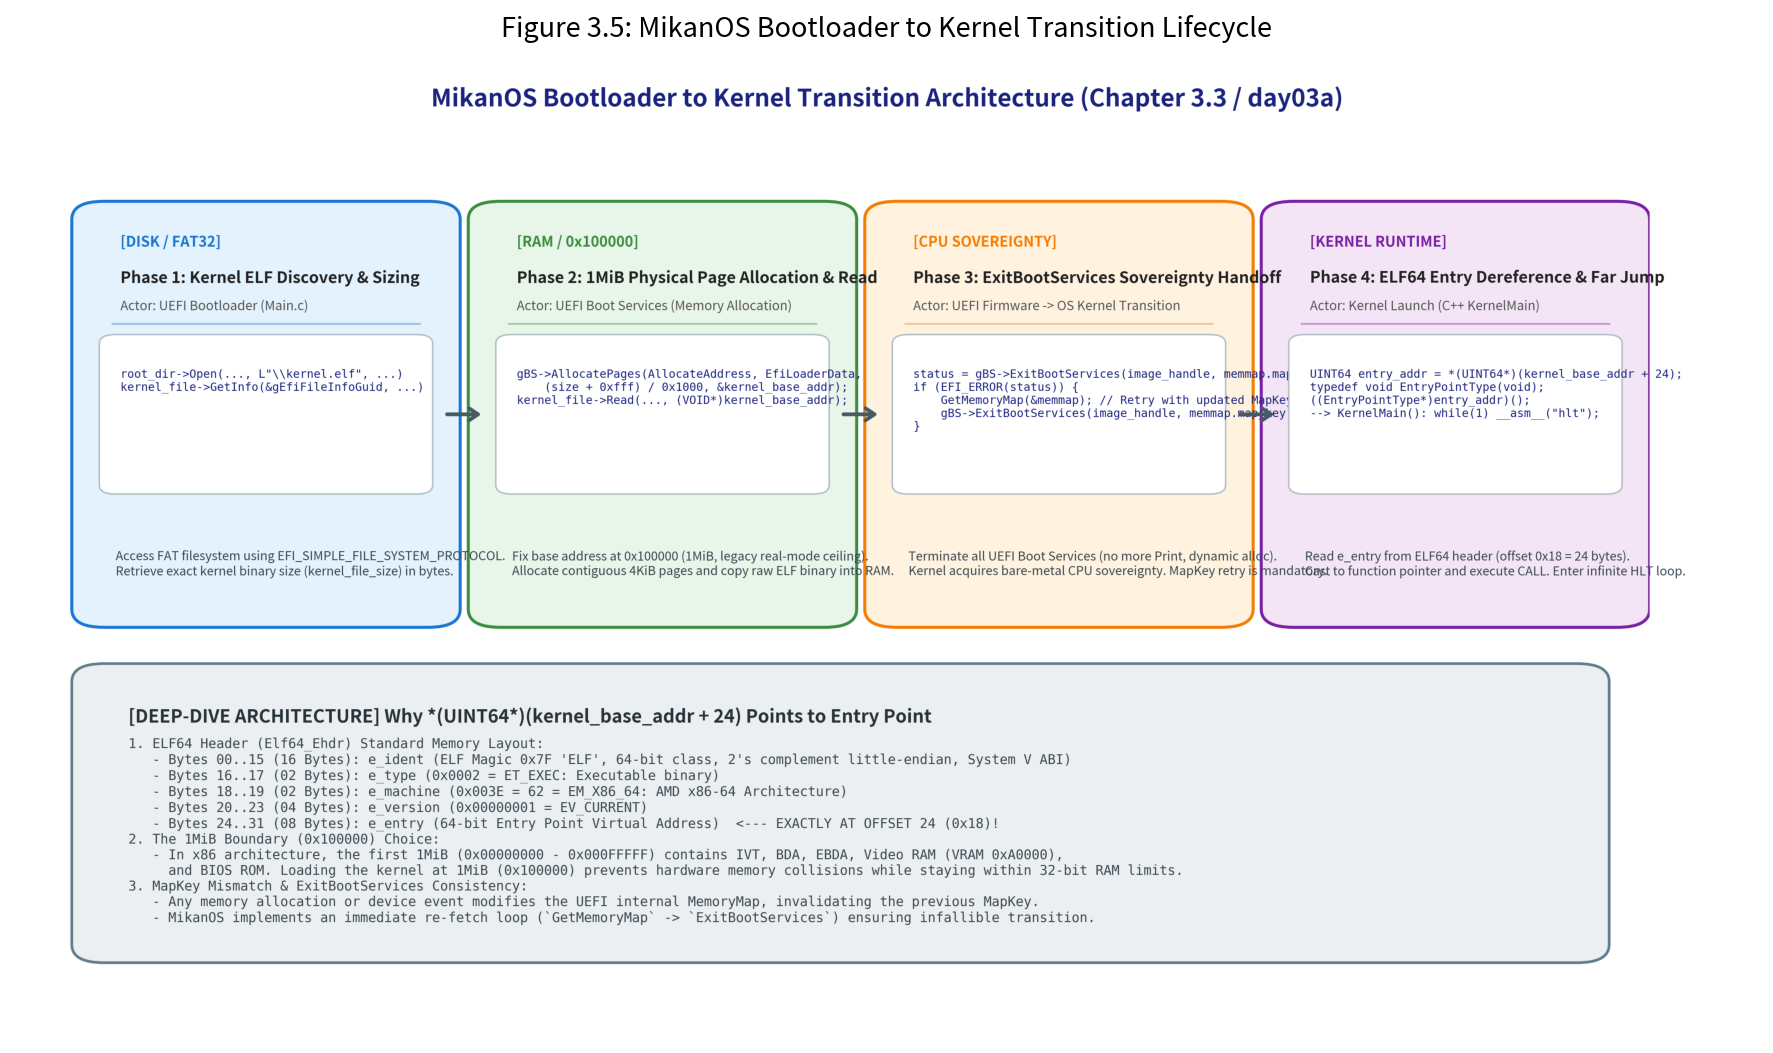

In [2]:
# === カーネルロード遷移アーキテクチャ図版の生成・表示 ===
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
from common import plot_kernel_loading_and_entry_flow

fig_path = Path("result/fig3_05_kernel_loading_and_entry_flow.png") if Path("result").exists() or Path.cwd().name == "3" else Path("3/result/fig3_05_kernel_loading_and_entry_flow.png")
plot_kernel_loading_and_entry_flow(str(fig_path))
print(f"高解像度図版を生成しました: {fig_path}")

img = Image.open(fig_path)
plt.figure(figsize=(15, 8.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 3.5: MikanOS Bootloader to Kernel Transition Lifecycle", fontsize=13, pad=10)
plt.show()


## 2. ELF64 ヘッダ構造とエントリポイント導出の数理

ブートローダ（`Main.c`）のカーネル起動コードに現れる謎めいた1行：
```c
UINT64 entry_addr = *(UINT64*)(kernel_base_addr + 24);
```
このコードは一体何を行っているのでしょうか？

MikanOS のカーネル `kernel.elf` は、標準的な 64 ビット **ELF (*Executable and Linkable Format*)** 形式の実行ファイルです。
ELF ファイルの先頭 64 バイトには、ファイル全体のメタ情報を定義する **`Elf64_Ehdr` (ELF-64 Header)** が必ず配置されています。

### ELF64 ヘッダ (`Elf64_Ehdr`) のメモリレイアウト表

| オフセット (10進) | オフセット (16進) | フィールド名 | 型 | サイズ | 内容・仕様 |
|:---:|:---:|:---|:---|:---:|:---|
| `0` | `0x00` | `e_ident[16]` | `unsigned char[16]` | 16B | ELF識別子 (`0x7F 'E' 'L' 'F'`, 64-bit, Little-Endian, ELF Ver.1, System V ABI) |
| `16` | `0x10` | `e_type` | `uint16_t` | 2B | ファイル種別 (`2 = ET_EXEC`: 実行可能バイナリ) |
| `18` | `0x12` | `e_machine` | `uint16_t` | 2B | アーキテクチャ (`0x3E = 62 = EM_X86_64`: AMD x86-64) |
| `20` | `0x14` | `e_version` | `uint32_t` | 4B | バージョン (`1 = EV_CURRENT`) |
| **`24`** | **`0x18`** | **`e_entry`** | **`uint64_t`** | **8B** | **エントリポイント仮想アドレス (最初に実行を開始すべきアドレス！)** |
| `32` | `0x20` | `e_phoff` | `uint64_t` | 8B | プログラムヘッダテーブルのファイルオフセット |
| `40` | `0x28` | `e_shoff` | `uint64_t` | 8B | セクションヘッダテーブルのファイルオフセット |
| `48` | `0x30` | `e_flags` | `uint32_t` | 4B | プロセッサ固有フラグ (x86-64 では通常 0) |
| `52` | `0x34` | `e_ehsize` | `uint16_t` | 2B | ELFヘッダ自身のサイズ (常に 64 バイト) |
| `54` | `0x36` | `e_phentsize` | `uint16_t` | 2B | プログラムヘッダエントリのサイズ (56 バイト) |
| `56` | `0x38` | `e_phnum` | `uint16_t` | 2B | プログラムヘッダの個数 |
| `58` | `0x3A` | `e_shentsize` | `uint16_t` | 2B | セクションヘッダエントリのサイズ (64 バイト) |
| `60` | `0x3C` | `e_shnum` | `uint16_t` | 2B | セクションヘッダの個数 |
| `62` | `0x3E` | `e_shstrndx` | `uint16_t` | 2B | セクション名文字列テーブルのインデックス |

### オフセット 24 の厳密な算術導出

$$\text{Offset}(e\_entry) = \text{Size}(e\_ident) + \text{Size}(e\_type) + \text{Size}(e\_machine) + \text{Size}(e\_version)$$
$$\text{Offset}(e\_entry) = 16 + 2 + 2 + 4 = 24 \text{ (バイト)} = 0x18 \text{ (16進数)}$$

したがって、`kernel_base_addr`（`0x100000`）に読み込まれた ELF バイナリの先頭から **24 バイト目** にある 64 ビット値（`UINT64`）をデリファレンスすると、リンカが設定したカーネルのエントリポイント関数（`KernelMain`）の実行開始アドレスが得られます！

### 関数ポインタへのキャストと間接呼び出し
取得した 64 ビット整数アドレスを C 言語で実行するために、関数ポインタ型を定義してキャストします：
```c
typedef void EntryPointType(void);            // 引数なし、戻り値 void の関数シグネチャ
EntryPointType* entry_point = (EntryPointType*)entry_addr; // 関数ポインタへキャスト
entry_point();                                // カーネルの KernelMain() へジャンプ！
```
コンパイラはこの `entry_point();` を、x86-64 機械語の `CALL RAX`（または `CALL RDX` などの間接 CALL 命令）にコンパイルし、CPU は `RIP` レジスタをカーネルの先頭番地へ切り替えて実行を開始します。

In [3]:
# === Python による ELF64 ヘッダ構築とオフセット 24 の検証 ===
from common import Elf64Header

# エントリポイント 0x100000 を持つ最小 ELF64 ヘッダを生成
elf_hdr = Elf64Header(e_entry=0x100000)
raw_elf_bytes = elf_hdr.to_bytes()

print(f"ELF64 ヘッダの総バイト長: {len(raw_elf_bytes)} バイト (規格値 64 バイトと完全一致)")
print(f"ELF マジックナンバー: {raw_elf_bytes[0:4]} (0x7F 'ELF')")
print(f"クラス (Bit 4): {raw_elf_bytes[4]} (2 = 64-bit architecture)")
print(f"エンディアン (Bit 5): {raw_elf_bytes[5]} (1 = 2's complement, Little Endian)")
print(f"アーキテクチャ (Offset 18..19): {hex(int.from_bytes(raw_elf_bytes[18:20], 'little'))} (0x3E = x86-64)")

# オフセット 24 から 8 バイト (UINT64) をデリファレンス
entry_point_val = int.from_bytes(raw_elf_bytes[24:32], byteorder="little")
print(f"\n[オフセット 24 デリファレンス結果]")
print(f"  *(UINT64*)(kernel_base_addr + 24) = {hex(entry_point_val)}")

# 導出解説の確認
info = elf_hdr.verify_entry_dereference(base_addr=0x100000)
print(f"\n検証レポート:\n{info['explanation']}")


ELF64 ヘッダの総バイト長: 64 バイト (規格値 64 バイトと完全一致)
ELF マジックナンバー: b'\x7fELF' (0x7F 'ELF')
クラス (Bit 4): 2 (2 = 64-bit architecture)
エンディアン (Bit 5): 1 (1 = 2's complement, Little Endian)
アーキテクチャ (Offset 18..19): 0x3e (0x3E = x86-64)

[オフセット 24 デリファレンス結果]
  *(UINT64*)(kernel_base_addr + 24) = 0x100000

検証レポート:
In 64-bit ELF (Elf64_Ehdr), e_ident occupies 16 bytes (offsets 0-15), e_type is 2 bytes (offsets 16-17), e_machine is 2 bytes (offsets 18-19), and e_version is 4 bytes (offsets 20-23). Therefore, e_entry begins exactly at offset 16 + 2 + 2 + 4 = 24 (0x18) as a 64-bit unsigned integer (UINT64). Reading *(UINT64*)(kernel_base_addr + 24) retrieves 0x100000.


## 3. ExitBootServices の深淵と MapKey リトライ機構

カーネルへジャンプする直前に実行される最も重大な処理が **`gBS->ExitBootServices`** です。

```c
EFI_STATUS status;
status = gBS->ExitBootServices(image_handle, memmap.map_key);
if (EFI_ERROR(status)) {
    status = GetMemoryMap(&memmap);
    if (EFI_ERROR(status)) {
        Print(L"failed to get memory map: %r\n", status);
        while (1);
    }
    status = gBS->ExitBootServices(image_handle, memmap.map_key);
    if (EFI_ERROR(status)) {
        Print(L"Could not exit boot service: %r\n", status);
        while (1);
    }
}
```

### なぜ ExitBootServices は失敗するのか？

UEFI 仕様書（*UEFI Specification*）では、`ExitBootServices` の第2引数として **`MapKey`**（メモリマップのバージョンキー）を渡すことが義務付けられています。

1. **ファームウェアの整合性チェック**:
   - `gBS->GetMemoryMap()` を呼んだ時点で、UEFI ファームウェアは現在のメモリマップに対してユニークな整数 `MapKey` を発行します。
   - もし `GetMemoryMap()` を呼んだ後から `ExitBootServices()` を呼ぶまでの間に、メモリの動的確保（`AllocatePages` / `AllocatePool`）やタイマイベント、デバイス通知などが割り込むと、ファームウェア内部のメモリ割り当て状態が変化します。
   - ファームウェアは「OS が把握しているメモリマップが最新状態ではない」と判断し、`EFI_INVALID_PARAMETER` を返して `ExitBootServices` を拒絶します！

2. **MikanOS のリトライ戦略**:
   - したがって、初回の `ExitBootServices` が失敗した場合は、直ちに `GetMemoryMap(&memmap)` を再実行して**最新の `MapKey` を取得し直して再度呼び出す**必要があります。
   - 2回目の呼び出し直前には余計なメモリ確保を行わないため、確実に成功します。

3. **ExitBootServices 完了後の絶対禁止事項**:
   - `ExitBootServices` が成功した瞬間、UEFI ブートサービス（`gBS` 経由の全関数、および `Print` などの標準出力関数）のコードやデータ構造は破棄対象領域（`EfiBootServicesCode` / `EfiBootServicesData`）へと格下げされます。
   - **これ以降に `Print()` などの UEFI 関数を呼び出すと、メモリ未定義アクセスで即座にトリプルフォールト（CPU リセット / クラッシュ）が発生します。**
   - これが、`Main.c` の末尾にある `Print(L"All done\n");` が `while(1);` の後ろに置かれ、実際には絶対に実行されない位置にある理由です。

In [4]:
# === Python による UEFI ブートローダシーケンスと MapKey リトライのシミュレーション ===
from common import KernelLoaderSimulator, KernelLoaderStep

loader = KernelLoaderSimulator(target_base_addr=0x100000)

# 1. カーネルファイルオープンとメタデータ取得
loader.open_kernel("\\kernel.elf", fake_binary_size=4096)
file_size = loader.get_kernel_info()

# 2. 1MiB 境界へのページ確保 (内部で MapKey が変化する)
base_addr, num_pages = loader.allocate_pages()

# 3. カーネル ELF バイナリのメモリ読み込み
loader.read_kernel_data()

print("[STEP 1..3 完了] 物理アドレス:", hex(base_addr), "確保ページ数:", num_pages)
print("現在のファームウェア最新 MapKey:", loader.map_key)

# 4. 古い MapKey (例: 42) で ExitBootServices を試行する (リトライなし)
stale_key = 42
res_fail = loader.exit_boot_services(passed_map_key=stale_key, retry_if_mismatch=False)
print(f"\n[実験 A] 古い MapKey={stale_key} による呼び出し結果: 成功={res_fail} (拒絶)")

# 5. MikanOS のリトライロジック有効下での試行
res_retry = loader.exit_boot_services(passed_map_key=stale_key, retry_if_mismatch=True)
print(f"[実験 B] リトライ有効下での呼び出し結果: 成功={res_retry} (最新キーで通過！)")

# 6. カーネルエントリポイントへのジャンプ
exec_result = loader.call_kernel_entry()
print(f"\n[カーネル突入成功]")
print(f"  エントリポイント: {exec_result['entry_point']}")
print(f"  最終CPU状態: {exec_result['final_cpu_state']}")


[STEP 1..3 完了] 物理アドレス: 0x100000 確保ページ数: 1
現在のファームウェア最新 MapKey: 49

[実験 A] 古い MapKey=42 による呼び出し結果: 成功=False (拒絶)
[実験 B] リトライ有効下での呼び出し結果: 成功=True (最新キーで通過！)

[カーネル突入成功]
  エントリポイント: 0x100000
  最終CPU状態: HLT (Halted / Interrupt Wait)


## 4. 【コラム 3.1】レッドゾーン (Red Zone) の罠

OS 自作初心者が最初に直面する最も不可解で致命的なバグが、**「レッドゾーン（Red Zone）」** に起因するスタック破壊です。

### レッドゾーンとは何か？ (System V AMD64 ABI 規約)

Linux や macOS などの x86-64 環境で標準採用されている **System V AMD64 ABI** では、スタックについて以下の最適化規則が定められています：

> **The 128-byte area beyond the location pointed to by `%rsp` is considered to be reserved and shall not be modified by signal or interrupt handlers. Therefore, functions may use this area for temporary data that is not needed across function calls. In particular, leaf functions may use this area for their entire stack frame, rather than adjusting the stack pointer in the prologue and epilogue.**
>
> *(現在 `%rsp` が指している位置からさらに下流の **128 バイト** の領域を **「レッドゾーン (Red Zone)」** と定義する。関数はこの領域を一時的なローカル変数格納に自由に使用してよい。特に、他の関数を呼び出さない葉関数 (Leaf Function) は、プロローグで `sub rsp, N` やエピローグで `add rsp, N` を実行することなく、この領域を丸ごとスタックフレームとして利用できる。)*

ユーザー空間アプリケーションでは、このレッドゾーンによって関数の呼び出しオーバーヘッド（命令数と実行クロックサイクル）を大幅に削減できます。

---

### なぜ OS カーネル開発ではレッドゾーンが「致命的な地雷」となるのか？

ユーザー空間アプリケーションであれば、シグナルハンドラが起動する際に OS カーネル側がレッドゾーンを避けてスタックフレームを積んでくれます。
しかし、**OS カーネル自身が実行されている最中に、タイマやキーボード・マウスなどのハードウェア割り込み、あるいは CPU 例外が発生した場合** はどうなるでしょうか？

```text
【標準 ABI (Red Zone 有効) の場合】
      +-----------------------------------------+
      | 呼び出し元のスタックフレーム            |
      +-----------------------------------------+
RSP ->| 現在のスタックポインタ                  |
======|=========================================|======
      | [Red Zone (128B)]                       |  <-- コンパイラが sub rsp せずに
      |  - local_var1 = 0x1234  (RSP - 8)       |      直接ローカル変数を配置！
      |  - local_var2 = 0x5678  (RSP - 16)      |
      +-----------------------------------------+
                         ▲
                         │ 💥 ハードウェア割り込みが発生！
                         │ CPU ハードウェアが現在の RSP の下に自動 PUSH！
                         │ (SS, RSP, RFLAGS, CS, RIP: 40バイト)
                         ▼
      +-----------------------------------------+
      | 割り込みフレーム (CPU が自動書き込み)   |  <-- local_var1, local_var2 が
      | [SS, RSP, RFLAGS, CS, RIP]              |      完全に上書きされて破壊される！
      +-----------------------------------------+
```

1. **CPU ハードウェアの仕様**:
   - x86-64 CPU は、割り込みが発生すると、**現在の `%rsp` の直下** に割り込み復帰用情報（`SS`, `RSP`, `RFLAGS`, `CS`, `RIP` 等の計 40 バイト）を自動的に PUSH して書き込みます。
   - **CPU ハードウェアは ABI のソフトウェア規約（Red Zone）など一切考慮しません！** 単に現在の `%rsp` から下に向かって機械的にデータを書き込みます。

2. **沈黙のデータ破壊 (Silent Data Corruption)**:
   - もしカーネル内の関数が Red Zone（`%rsp - 8` など）に重要なポインタや計算変数を保持していた場合、タイマ割り込みが1回入った瞬間にその変数が上書き破壊されます。
   - 割り込みハンドラから `iretq` で元の関数に戻ったとき、関数は破壊されたポインタを参照して不正メモリアクセスを起こし、原因究明が極めて困難な謎のクラッシュを引き起こします。

### 解決策: コンパイルオプション `-mno-red-zone`

この致命的な問題を回避するため、OS カーネルをビルドする際は、コンパイラ（Clang / GCC）に対して **`-mno-red-zone`** フラグを必ず指定します：

```bash
clang++ ... -mno-red-zone ... -c main.cpp
```

`-mno-red-zone` を指定すると、コンパイラは Red Zone の使用を完全に禁止し、ローカル変数を使用する際は必ず **`sub rsp, N`** を発行してスタックポインタ自身を変数の下流まで移動させます。
これにより、ハードウェア割り込みがいつ発生しても、CPU が自動 PUSH する領域はローカル変数のさらに下側となり、変数が破壊されることは絶対にありません！

高解像度図版を生成しました: result/fig3_06_red_zone_mechanism_and_trap.png


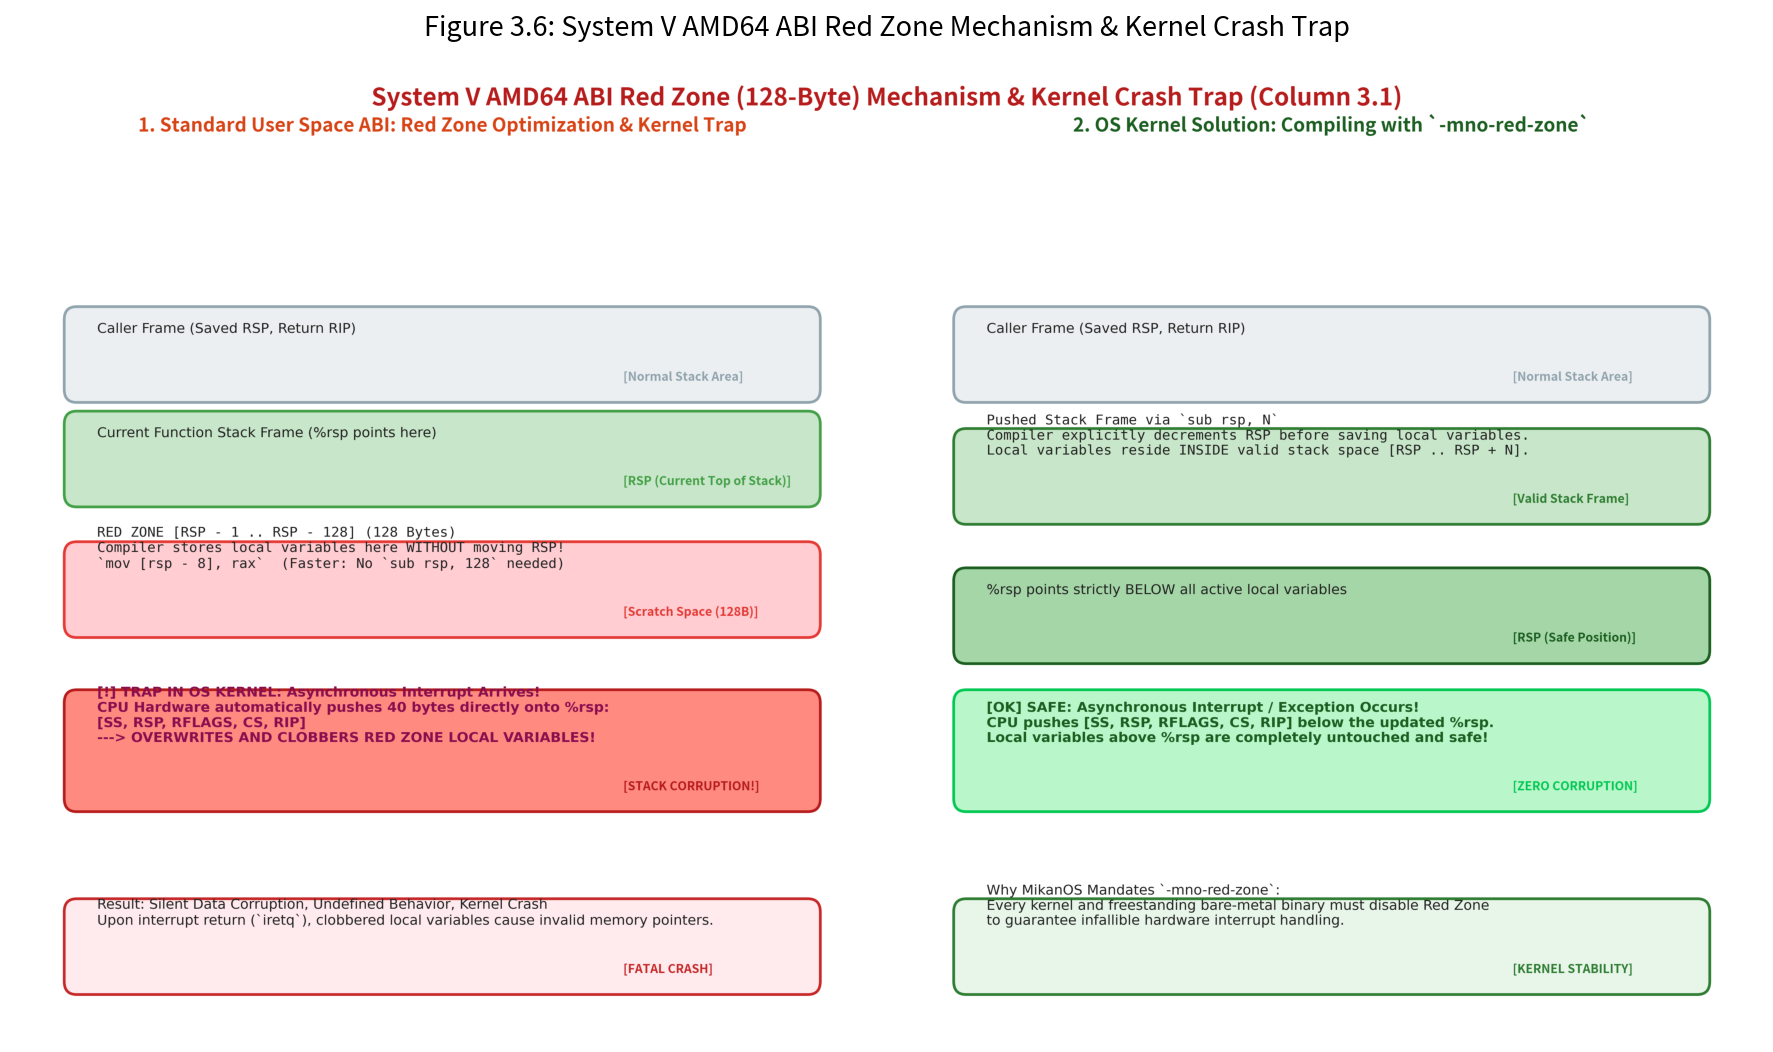

In [5]:
# === レッドゾーンの仕組みと割り込みスタック破壊の比較図版の生成・表示 ===
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
from common import plot_red_zone_mechanism_and_trap

fig_red_path = Path("result/fig3_06_red_zone_mechanism_and_trap.png") if Path("result").exists() or Path.cwd().name == "3" else Path("3/result/fig3_06_red_zone_mechanism_and_trap.png")
plot_red_zone_mechanism_and_trap(str(fig_red_path))
print(f"高解像度図版を生成しました: {fig_red_path}")

img_red = Image.open(fig_red_path)
plt.figure(figsize=(15, 8.5), dpi=150)
plt.imshow(img_red)
plt.axis("off")
plt.title("Figure 3.6: System V AMD64 ABI Red Zone Mechanism & Kernel Crash Trap", fontsize=13, pad=10)
plt.show()


In [6]:
# === Python によるレッドゾーンスタック破壊シミュレーション ===
from common import RedZoneSimulator

print("=== [実験 1] 標準 ABI (Red Zone 有効) でのカーネル割り込み ===")
sim_bad = RedZoneSimulator()
sim_bad.configure_compiler_mode(use_red_zone=True)

# 葉関数が 3 つのローカル変数を Red Zone (RSP-8, RSP-16, RSP-24) に格納
sim_bad.allocate_leaf_function_vars({
    "important_kernel_ptr": 0xDEADBEEFCAFEBABE,
    "loop_index": 0x0000000000000064,
    "status_code": 0x0000000000000000,
})
print(f"変数配置直後の RSP: {hex(sim_bad.rsp)} (RSP は一切減算されていない！)")

# タイマ割り込みが到着！
corrupt_log = sim_bad.trigger_hardware_interrupt(vector=32)
for log_line in corrupt_log:
    print("  ->", log_line)
print(f"破壊されたローカル変数数: {sim_bad.count_corrupted_variables()} / 3 (全滅！)")

print("\n=== [実験 2] カーネル ABI (-mno-red-zone 有効) でのカーネル割り込み ===")
sim_safe = RedZoneSimulator()
sim_safe.configure_compiler_mode(use_red_zone=False) # -mno-red-zone

# コンパイラが `sub rsp, 32` を実行してからローカル変数を格納
sim_safe.allocate_leaf_function_vars({
    "important_kernel_ptr": 0xDEADBEEFCAFEBABE,
    "loop_index": 0x0000000000000064,
    "status_code": 0x0000000000000000,
})
print(f"変数配置直後の RSP: {hex(sim_safe.rsp)} (RSP が安全に変数の下流へ移動！)")

# タイマ割り込みが到着！
safe_log = sim_safe.trigger_hardware_interrupt(vector=32)
print(f"破壊ログ: {len(safe_log)} 件 (CPUは安全な新RSPの下に書き込んだ)")
print(f"破壊されたローカル変数数: {sim_safe.count_corrupted_variables()} / 3 (完全無傷！)")


=== [実験 1] 標準 ABI (Red Zone 有効) でのカーネル割り込み ===
変数配置直後の RSP: 0x7fffffff0000 (RSP は一切減算されていない！)
  -> CRITICAL CORRUPTION: Variable 'important_kernel_ptr' at 0x7ffffffefff8 (original value 0xdeadbeefcafebabe) was OVERWRITTEN by CPU hardware pushing Interrupt_SS (0x10)!
  -> CRITICAL CORRUPTION: Variable 'loop_index' at 0x7ffffffefff0 (original value 0x64) was OVERWRITTEN by CPU hardware pushing Interrupt_RSP (0x7fffffff0000)!
  -> CRITICAL CORRUPTION: Variable 'status_code' at 0x7ffffffeffe8 (original value 0x0) was OVERWRITTEN by CPU hardware pushing Interrupt_RFLAGS (0x202)!
破壊されたローカル変数数: 3 / 3 (全滅！)

=== [実験 2] カーネル ABI (-mno-red-zone 有効) でのカーネル割り込み ===
変数配置直後の RSP: 0x7ffffffeffe0 (RSP が安全に変数の下流へ移動！)
破壊ログ: 0 件 (CPUは安全な新RSPの下に書き込んだ)
破壊されたローカル変数数: 0 / 3 (完全無傷！)


## 5. 初めてのカーネル実装とビルドコマンドの全容

本節（`day03a`）で作成する最小のカーネルソースコード（`kernel/main.cpp`）は、わずか 3 行です：

```cpp
extern "C" void KernelMain() {
  while (1) __asm__("hlt");
}
```

### 各行の意味と低レイヤ解説
1. **`extern "C"`**:
   - C++ コンパイラによる**名前マングリング（Name Mangling）**を無効化します。
   - C++ では関数のオーバーロードを可能にするため、シンボル名に引数情報等を付加した複雑な名前（例: `_Z10KernelMainv` 等）に変換されます。`extern "C"` を指定することで、シンボル名をそのまま `KernelMain` として出力させ、リンカやブートローダから一意に特定できるようにします。
2. **`while (1) __asm__("hlt");`**:
   - インラインアセンブラで **`hlt` (*Halt*)** 命令を実行し続けます。
   - `hlt` 命令は、次の外部割り込みが到着するまで CPU を低電力スタンバイ状態に移行させます。単なる空ループ `while (1);` に比べ、CPU の過熱や消費電力を劇的に抑制します。

---

### カーネルのコンパイルとリンクコマンド詳細

MikanOS では、Clang と LLD（LLVM リンカ）を用いてカーネルをビルドします：

```bash
# 1. コンパイル (main.cpp -> main.o)
clang++ -O2 -Wall -g --target=x86_64-elf -ffreestanding \
        -mno-red-zone -fno-exceptions -fno-rtti -std=c++17 -c main.cpp

# 2. リンク (main.o -> kernel.elf)
ld.lld --entry KernelMain -z norelro --image-base 0x100000 --static -o kernel.elf main.o
```

| フラグ名 | 役割と理由 |
|:---|:---|
| `--target=x86_64-elf` | Linux 等のホスト環境に依存せず、独立した 64 ビット ELF オブジェクトを出力する |
| **`-ffreestanding`** | OS や C/C++ 標準ライブラリが存在しない**自立環境（Freestanding Environment）**向けコードとしてコンパイルする |
| **`-mno-red-zone`** | **【必須】** 前述の通り、スタック下流 128 バイトのレッドゾーン使用を禁止し、割り込みによるスタック破壊を防ぐ |
| `-fno-exceptions` | C++ の例外処理機構（スタック巻き戻しや例外テーブル）を無効化する（カーネル初期段階では未対応のため） |
| `-fno-rtti` | C++ の実行時型情報（`typeid` や `dynamic_cast`）を無効化し、バイナリサイズと不要なメタデータを削減する |
| `--entry KernelMain` | ELF ヘッダの `e_entry` に `KernelMain` 関数のアドレスを記録する |
| `--image-base 0x100000` | ベースアドレスを物理番地 `0x100000` (1MiB) として絶対アドレス解決を行う |
| `-z norelro` | 読み取り専用再配置（Relocation Read-Only）セクション生成を無効化し、最小バイナリ構造にする |
| `--static` | 共有ライブラリへの動的リンクを一切行わず、完全静的バイナリとする |


In [7]:
# === ホスト側 C++20 スタンドアロン検証コードのコンパイルと実行 ===
import subprocess
from pathlib import Path

# src/ch03/first_kernel_sim.cpp の存在確認とコンパイル
cpp_source = Path("src/ch03/first_kernel_sim.cpp")
if not cpp_source.exists():
    cpp_source = Path("../src/ch03/first_kernel_sim.cpp")

bin_output = Path("build/bin/ch03_first_kernel_sim")
bin_output.parent.mkdir(parents=True, exist_ok=True)

compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra",
    str(cpp_source), "-o", str(bin_output)
]
print("C++20 コードをコンパイル中:", " ".join(compile_cmd))
res = subprocess.run(compile_cmd, capture_output=True, text=True)
if res.returncode != 0:
    print("コンパイルエラー:", res.stderr)
else:
    print("コンパイル成功！")
    # --test 引数で内蔵テストスイートを実行
    run_res = subprocess.run([str(bin_output), "--test"], capture_output=True, text=True)
    print(run_res.stdout)


C++20 コードをコンパイル中: g++ -std=c++20 -O2 -Wall -Wextra ../src/ch03/first_kernel_sim.cpp -o build/bin/ch03_first_kernel_sim


コンパイル成功！
[TEST] 1. ELF64 Header Structure and Offset 24...
  -> PASSED: ELF64 offset 24 dereference verified.
[TEST] 2. Bootloader Transition & ExitBootServices Retry...
  -> PASSED: Bootloader transition and ExitBootServices verified.
[TEST] 3. Red Zone Stack Corruption Trap in Kernel Mode...
  -> PASSED: Red Zone stack destruction reproduced.
[TEST] 4. Safe Stack with -mno-red-zone in Kernel Mode...
  -> PASSED: -mno-red-zone immunity to interrupt corruption verified.

>>> ALL FIRST KERNEL & RED ZONE SIMULATION TESTS PASSED! <<<




## 6. 本節のまとめと次節への展望

### 本節で達成したこと (Checklist)
- [x] ブートローダとカーネルの責務境界を理解し、なぜカーネルを独立バイナリとして分離するのかを把握した
- [x] UEFI `Open`, `GetInfo`, `AllocatePages` による 1MiB（`0x100000`）境界へのカーネルバイナリ展開フローをトレースした
- [x] `ExitBootServices` の役割と、`MapKey` 不一致による失敗時の再取得（リトライ）の必然性を実証した
- [x] 64ビット ELF ヘッダ構造の数理計算に基づき、なぜ `*(UINT64*)(kernel_base_addr + 24)` でエントリポイントが取得できるのかを導出した
- [x] 【コラム3.1】System V AMD64 ABI レッドゾーン（Red Zone）の仕組みと、OS カーネルにおいて `-mno-red-zone` が絶対必須である理由（非同期割り込みによるスタック破壊）を完全に理解した
- [x] `KernelMain` を `hlt` ループで実装し、自立環境（Freestanding）向けビルドフラグの全貌を整理した

### 次節への接続: 3.4 ブートローダからピクセルを描く (`osbook_day03b`)
本節でカーネルの起動には成功しましたが、現在のカーネルは画面に何も表示せず、ただ `hlt` ループで沈黙しているだけです。
画面が真っ暗なままでは、カーネルが正常に動いているのか、途中でクラッシュしているのか判別できません。

次節 **3.4** では、UEFI のグラフィックス機能である **GOP (*Graphics Output Protocol*)** を利用して、フレームバッファ（画面のピクセルが配置されたメモリ領域）のベースアドレスと解像度を取得し、ブートローダ側から画面全体にピクセルを描画する実験へと進みます！